In [6]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
from PIL import Image

In [7]:
if torch.cuda.is_available():
    print("CUDA is available!")
    print("Number of GPUs:", torch.cuda.device_count())
    print("Current GPU index:", torch.cuda.current_device())
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("CUDA is NOT available. Using CPU.")

CUDA is NOT available. Using CPU.


### Dataset
https://huggingface.co/datasets/LujianYao/HSSDataset

In [8]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms.functional as TF

class HSSSegmentationDatasetPyTorch2(Dataset):
    """
    A PyTorch Dataset class for loading segmentation datasets using .txt split files.
    Expected structure:
    - dataset_root/images/*.npy
    - dataset_root/masks/*.png
    - dataset_root/[train|val|test].txt (containing list of filenames without extensions)
    """
    def __init__(
        self,
        dataset_root="/content/HSSDataset",
        image_dir="npy_multichannel",
        mask_dir="Mask",
        image_size=(216, 408), 
        split="train",
        img_ext=".npy",
        mask_ext=".png",
        img_channels=25,
        mask_channels=1,
        data_version='original'
    ):
        self.dataset_root = dataset_root
        self.image_dir = os.path.join(dataset_root, image_dir)
        self.mask_dir = os.path.join(dataset_root, mask_dir)
        self.image_size = image_size
        self.split = split
        self.img_ext = img_ext
        self.mask_ext = mask_ext
        self.img_channels = img_channels
        self.mask_channels = mask_channels
        self.data_version = data_version
        
        self.image_paths = []
        self.mask_paths = []
        
        self._load_paths()

    def _load_paths(self):
        # Path to the .txt file (e.g., /content/HSSDataset_Splitted/train.txt)
        split_file = os.path.join(self.dataset_root, "split", self.data_version, f"{self.split}.txt")
        
        print(f"Reading {self.split} split from: {split_file}")
        
        if not os.path.exists(split_file):
            print(f"Error: Split file not found: {split_file}")
            return

        with open(split_file, 'r') as f:
            # Read lines and strip whitespace/newlines
            filenames = [line.strip() for line in f if line.strip()]

        for base_filename in filenames:
            img_filename = base_filename + self.img_ext
            mask_filename = base_filename + self.mask_ext

            img_filepath = os.path.join(self.image_dir, img_filename)
            mask_filepath = os.path.join(self.mask_dir, mask_filename)

            if os.path.exists(img_filepath) and os.path.exists(mask_filepath):
                self.image_paths.append(img_filepath)
                self.mask_paths.append(mask_filepath)
            else:
                if not os.path.exists(img_filepath):
                    print(f"Warning: Image missing: {img_filepath}")
                if not os.path.exists(mask_filepath):
                    print(f"Warning: Mask missing: {mask_filepath}")

        print(f"Found {len(self.image_paths)} valid image-mask pairs for split '{self.split}'.")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        # Load hyperspectral .npy file and crop
        image = np.load(image_path).astype(np.float32)[:-1, :-1, :]
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Read and decode mask
        mask = Image.open(mask_path).convert("L")

        # Resize to (H+1, W+1) then crop to (H, W) to match TF logic
        target_h, target_w = self.image_size
        mask = TF.resize(mask, (target_h + 1, target_w + 1), interpolation=TF.InterpolationMode.NEAREST)
        mask = np.array(mask)[:-1, :-1]

        # Convert mask to binary (0 or 1)
        mask = (mask > 0).astype(np.uint8)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

# --- Usage Example ---
print("\n--- Loading HSSSegmentationDatasetPyTorch with .txt Splits ---")
BATCH_SIZE = 16
DATA_VERSION = 'v2'
DATASET_ROOT="./HSSDataset/HSS_VOC"

train_segmentation_data = HSSSegmentationDatasetPyTorch2(
    dataset_root=DATASET_ROOT,
    split="train",
    image_size=(216, 408),
    data_version=DATA_VERSION
)

train_dataloader = DataLoader(
    train_segmentation_data, 
    batch_size=BATCH_SIZE, 
    shuffle=True
)

val_segmentation_data = HSSSegmentationDatasetPyTorch2(
    dataset_root=DATASET_ROOT,
    split="val",
    image_size=(216, 408),
    data_version=DATA_VERSION
)

val_dataloader = DataLoader(
    val_segmentation_data, 
    batch_size=BATCH_SIZE, 
    # shuffle=True
)


test_segmentation_data = HSSSegmentationDatasetPyTorch2(
    dataset_root=DATASET_ROOT,
    split="test",
    image_size=(216, 408),
    data_version=DATA_VERSION
)

test_dataloader = DataLoader(
    test_segmentation_data, 
    batch_size=BATCH_SIZE, 
    # shuffle=True
)

print("Type of train dataloader: ", type(train_dataloader))


--- Loading HSSSegmentationDatasetPyTorch with .txt Splits ---
Reading train split from: ./HSSDataset/HSS_VOC\split\v2\train.txt
Found 587 valid image-mask pairs for split 'train'.
Reading val split from: ./HSSDataset/HSS_VOC\split\v2\val.txt
Found 118 valid image-mask pairs for split 'val'.
Reading test split from: ./HSSDataset/HSS_VOC\split\v2\test.txt
Found 302 valid image-mask pairs for split 'test'.
Type of train dataloader:  <class 'torch.utils.data.dataloader.DataLoader'>


In [9]:
if train_dataloader:
    for image_batch, mask_batch in train_dataloader:
        print(f"Shape of one image batch from train dataloader: {image_batch.shape}") # (batch_size, channels, image_height, image_width)
        print(f"Shape of one mask batch from train dataloader: {mask_batch.shape}") # (batch_size, 1, mask_height, mask_width)
        print(f"Example mask pixel values (first image in batch, top-left corner):\n {mask_batch[0, 0, :5, :5].numpy()}")
        break
else:
    print("Failed to create PyTorch training dataloader. Check warnings above.")


if val_dataloader:
    for image_batch, mask_batch in val_dataloader:
        print(f"Shape of one image batch from validation dataloader: {image_batch.shape}") # (batch_size, channels, image_height, image_width)
        print(f"Shape of one mask batch from validation dataloader: {mask_batch.shape}") # (batch_size, 1, mask_height, mask_width)
        break
else:
    print("Failed to create PyTorch validation dataloader. Check warnings above.")

if test_dataloader:
    for image_batch, mask_batch in test_dataloader:
        print(f"Shape of one image batch from test dataloader: {image_batch.shape}") # (batch_size, channels, image_height, image_width)
        print(f"Shape of one mask batch from test dataloader: {mask_batch.shape}") # (batch_size, 1, mask_height, mask_width)
        break
else:
    print("Failed to create PyTorch test dataloader. Check warnings above.")

Shape of one image batch from train dataloader: torch.Size([16, 25, 216, 408])
Shape of one mask batch from train dataloader: torch.Size([16, 1, 216, 408])
Example mask pixel values (first image in batch, top-left corner):
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
Shape of one image batch from validation dataloader: torch.Size([16, 25, 216, 408])
Shape of one mask batch from validation dataloader: torch.Size([16, 1, 216, 408])
Shape of one image batch from test dataloader: torch.Size([16, 25, 216, 408])
Shape of one mask batch from test dataloader: torch.Size([16, 1, 216, 408])


In [ ]:
import torch
import torch.nn as nn
import torchinfo # Import torchinfo


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.branch_1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same', bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.branch_2 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same', dilation=2, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        out1 = self.branch_1(x)
        out2 = self.branch_2(x)

        # Check shapes at runtime
        if out1.shape != out2.shape:
            raise ValueError(f"Shape mismatch: {out1.shape} vs {out2.shape}")

        return out1 + out2  # Element-wise addition

class UNet(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(UNet, self).__init__()

        # Encoder
        self.encoder_conv1 = ConvBlock(in_channels, 8)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.encoder_conv2 = ConvBlock(8, 16)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.encoder_conv3 = ConvBlock(16, 32)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck
        self.bottleneck_conv = ConvBlock(32, 16)

        # Decoder
        # UpSampling2D((2,2)) is approximated by nn.Upsample with scale_factor=2
        # Keras Concatenate()([u1, c2]) means the channels are added
        self.upsample1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.decoder_conv1 = ConvBlock(16 + 32, 32) # Concatenate upsampled bottleneck (16) and c3 (32)

        self.upsample2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.decoder_conv2 = ConvBlock(32 + 16, 16) # Concatenate upsampled decoder_conv1 (32) and c2 (16)

        self.upsample3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.decoder_conv3 = ConvBlock(16 + 8, 8) # Concatenate upsampled decoder_conv2 (16) and c1 (8)

        # Output: Keras Conv2D(1, (3, 3), padding='same', activation='sigmoid')
        self.out_conv = nn.Conv2d(8, num_classes, kernel_size=3, padding='same')
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x is (Batch, Channels, Height, Width)

        # Encoder
        c1 = self.encoder_conv1(x)
        p1 = self.pool1(c1)

        c2 = self.encoder_conv2(p1)
        p2 = self.pool2(c2)

        c3 = self.encoder_conv3(p2)
        p3 = self.pool3(c3)

        # Bottleneck
        c4 = self.bottleneck_conv(p3)

        # Decoder
        u1 = self.upsample1(c4)
        # Ensure spatial dimensions match before concatenation if necessary
        # Keras Concatenate implies they are compatible after upsampling
        u1 = torch.cat([u1, c3], dim=1) # Concatenate along channel dimension
        c5 = self.decoder_conv1(u1)

        u2 = self.upsample2(c5)
        # Ensure spatial dimensions match before concatenation if necessary
        u2 = torch.cat([u2, c2], dim=1) # Concatenate along channel dimension
        c6 = self.decoder_conv2(u2)

        u3 = self.upsample3(c6)
        # Ensure spatial dimensions match before concatenation if necessary
        u3 = torch.cat([u3, c1], dim=1) # Concatenate along channel dimension
        c7 = self.decoder_conv3(u3)

        # Output
        outputs = self.out_conv(c7)
        outputs = self.sigmoid(outputs)

        return outputs

    def summary(self, input_size): # Add input_size argument for dummy input
        """Prints a summary of the model, including layer-wise and total parameter counts and output shapes."""
        # Use torchinfo.summary
        # input_size should be (batch_size, channels, height, width)
        print("\n" + "="*70)
        print(f"Model Summary: {self.__class__.__name__}")
        print("="*70)
        torchinfo.summary(
            self,
            input_size=input_size,
            verbose=1,
            depth=3,
            col_names=["input_size", "kernel_size", "output_size", "num_params", "params_percent", "mult_adds", "trainable"]
        )
        print("="*70 + "\n")

# Example usage:
INPUT_CHANNELS = 25 # Matches the input_shape=(216, 408, 25) from Keras
NUM_CLASSES = 1     # Binary segmentation
IMAGE_HEIGHT = 216  # From image_size in HSSSegmentationDatasetPyTorch
IMAGE_WIDTH = 408   # From image_size in HSSSegmentationDatasetPyTorch

model = UNet(in_channels=INPUT_CHANNELS, num_classes=NUM_CLASSES)
# Create a dummy input for the summary
dummy_input_size = (1, INPUT_CHANNELS, IMAGE_HEIGHT, IMAGE_WIDTH) # Batch size 1
model.summary(input_size=dummy_input_size)


Model Summary: UNet
Layer (type:depth-idx)                   Input Shape               Kernel Shape              Output Shape              Param #                   Param %                   Mult-Adds                 Trainable
UNet                                     [1, 25, 216, 408]         --                        [1, 1, 216, 408]          --                             --                   --                        True
├─ConvBlock: 1-1                         [1, 25, 216, 408]         --                        [1, 8, 216, 408]          --                             --                   --                        True
│    └─Sequential: 2-1                   [1, 25, 216, 408]         --                        [1, 8, 216, 408]          --                             --                   --                        True
│    │    └─Conv2d: 3-1                  [1, 25, 216, 408]         [3, 3]                    [1, 8, 216, 408]          1,800                       2.58%              

In [11]:
import torch
import torch.nn.functional as F

def dice_loss(y_true, y_pred):
    smooth = 1e-6

    y_true = y_true.float()
    y_pred = y_pred.float()

    # Flatten y_true and y_pred to 1D vectors for global sum
    y_true_f = y_true.reshape(-1)
    y_pred_f = y_pred.reshape(-1)

    intersection = torch.sum(y_true_f * y_pred_f)
    union = torch.sum(y_true_f) + torch.sum(y_pred_f)

    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - dice

def per_sample_dice_loss(y_true, y_pred):
    """
    Calculates Dice Loss for (batch_size, channels, height, width)
    by averaging the Dice score of each sample individually.
    """
    smooth = 1e-6

    y_true = y_true.float()
    y_pred = y_pred.float()

    # Define the dimensions to reduce (Channels, Height, Width)
    # This leaves the Batch dimension (axis 0) intact.
    reduction_dims = (1, 2, 3) # For (N, C, H, W) tensors

    # Calculate Intersection and Union per sample
    intersection = torch.sum(y_true * y_pred, dim=reduction_dims)
    union = torch.sum(y_true, dim=reduction_dims) + torch.sum(y_pred, dim=reduction_dims)

    # Dice score per sample: shape is (batch_size,)
    dice = (2. * intersection + smooth) / (union + smooth)

    # Average the Dice scores across the batch and subtract from 1 for Loss
    return 1 - torch.mean(dice)

def bce_dice_loss(y_true, y_pred, alpha=0.3):
    # y_true and y_pred are (N, C, H, W)
    bce = F.binary_cross_entropy(y_pred, y_true.float(), reduction='mean')
    d_loss = per_sample_dice_loss(y_true, y_pred)

    return alpha * bce + (1 - alpha) * d_loss


In [12]:
import torch

def _get_per_sample_tensors(y_true, y_pred):
    """Helper to prepare y_true and y_pred for per-sample metric calculation."""
    y_pred_binary = (y_pred > 0.5).float()
    y_true_float = y_true.float()
    return y_true_float, y_pred_binary

# Define the dimensions to sum over for per-sample calculation (C, H, W)
# Assuming input tensors are (Batch, Channel, Height, Width)
REDUCTION_DIMS = (1, 2, 3)

def f1_score(y_true, y_pred):
    y_true_float, y_pred_binary = _get_per_sample_tensors(y_true, y_pred)

    tp = torch.sum(y_true_float * y_pred_binary, dim=REDUCTION_DIMS)
    fp = torch.sum((1 - y_true_float) * y_pred_binary, dim=REDUCTION_DIMS)
    fn = torch.sum(y_true_float * (1 - y_pred_binary), dim=REDUCTION_DIMS)

    # Calculate F1 score per sample, then average across the batch
    f1_per_sample = (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)
    return torch.mean(f1_per_sample)

def mean_iou(y_true, y_pred):
    y_true_float, y_pred_binary = _get_per_sample_tensors(y_true, y_pred)

    intersection = torch.sum(y_true_float * y_pred_binary, dim=REDUCTION_DIMS)
    union = torch.sum(y_true_float, dim=REDUCTION_DIMS) + torch.sum(y_pred_binary, dim=REDUCTION_DIMS) - intersection

    # Calculate IoU per sample, then average across the batch
    iou_per_sample = (intersection + 1e-6) / (union + 1e-6)
    return torch.mean(iou_per_sample)

def precision(y_true, y_pred):
    y_true_float, y_pred_binary = _get_per_sample_tensors(y_true, y_pred)

    tp = torch.sum(y_true_float * y_pred_binary, dim=REDUCTION_DIMS)
    fp = torch.sum((1 - y_true_float) * y_pred_binary, dim=REDUCTION_DIMS)

    # Calculate Precision per sample, then average across the batch
    precision_per_sample = (tp + 1e-6) / (tp + fp + 1e-6)
    return torch.mean(precision_per_sample)

def recall(y_true, y_pred):
    y_true_float, y_pred_binary = _get_per_sample_tensors(y_true, y_pred)

    tp = torch.sum(y_true_float * y_pred_binary, dim=REDUCTION_DIMS)
    fn = torch.sum(y_true_float * (1 - y_pred_binary), dim=REDUCTION_DIMS)

    # Calculate Recall per sample, then average across the batch
    recall_per_sample = (tp + 1e-6) / (tp + fn + 1e-6)
    return torch.mean(recall_per_sample)

In [13]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np


class SegmentationTrainer:
    """
    Trainer class for UNet segmentation model in PyTorch.

    Handles model creation, training, evaluation, and saving.
    """
    def __init__(self, train_dataloader, val_dataloader, test_dataloader, input_channels, num_classes, learning_rate, device):
        self.train_dataloader = train_dataloader
        self.val_dataloader = val_dataloader
        self.test_dataloader = test_dataloader
        self.input_channels = input_channels
        self.num_classes = num_classes
        self.learning_rate = learning_rate
        self.device = device

        self.model = None
        self.optimizer = None
        self.criterion = None
        # Initialize history dict for storing metrics
        self.history = {'loss': [], 'val_loss': [], 'f1_score': [], 'val_f1_score': [],
                        'mean_iou': [], 'val_mean_iou': [], 'precision': [], 'val_precision': [],
                        'recall': [], 'val_recall': []}

    def build_model(self):
        """Build the UNet model, define optimizer and loss function."""
        print("Building PyTorch UNet model...")
        self.model = UNet(in_channels=self.input_channels, num_classes=self.num_classes).to(self.device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.criterion = bce_dice_loss # Using the combined BCE and Dice loss

        print("Model, optimizer, and loss function initialized successfully!")
        # For PyTorch, model.summary() isn't a standard method like Keras,
        # but we can print the model structure.
        # print(self.model) # Uncomment to print model architecture

    def _calculate_metrics(self, outputs, masks):
        """Helper to calculate metrics for a batch."""
        # Ensure outputs are detached from graph and on CPU for numpy conversion
        # Metric functions expect torch tensors
        outputs = outputs.detach().cpu()
        masks = masks.detach().cpu()

        # The metric functions expect (N, C, H, W) where C is 1 for binary
        current_f1 = f1_score(masks, outputs)
        current_miou = mean_iou(masks, outputs)
        current_precision = precision(masks, outputs)
        current_recall = recall(masks, outputs)
        return current_f1, current_miou, current_precision, current_recall

    def train(self, epochs=50, save_path="../models"):
        """
        Train the model.

        Args:
            epochs: Number of training epochs
            save_path: Path to save model checkpoints

        Returns:
            Training history
        """
        os.makedirs(save_path, exist_ok=True)
        self.build_model() # Build model and define optimizer/criterion

        print("\n" + "="*50)
        print("Starting training...")
        print(f"Epochs: {epochs}")
        print(f"Batch size: {self.train_dataloader.batch_size}")
        print(f"Learning rate: {self.learning_rate}")
        print(f"Device: {self.device}")
        print("="*50 + "\n")

        best_val_miou = -1.0
        patience_counter = 0
        early_stopping_patience = 20
        reduce_lr_patience = 5
        lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(self.optimizer, mode='max', factor=0.5, patience=reduce_lr_patience, min_lr=1e-7)

        for epoch in range(epochs):
            self.model.train()
            total_loss = 0.0
            total_f1 = 0.0
            total_miou = 0.0
            total_precision = 0.0
            total_recall = 0.0
            num_batches = 0

            print(f"Epoch {epoch+1}/{epochs}")
            for batch_idx, (images, masks) in enumerate(self.train_dataloader):
                images = images.to(self.device)
                masks = masks.to(self.device)

                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(masks, outputs)
                loss.backward()
                self.optimizer.step()

                total_loss += loss.item()
                f1, miou, prec, rec = self._calculate_metrics(outputs, masks)
                total_f1 += f1
                total_miou += miou
                total_precision += prec
                total_recall += rec
                num_batches += 1

                # if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(self.train_dataloader):
                print(f"  Batch {batch_idx+1}/{len(self.train_dataloader)} - Loss: {loss.item():.4f}", end='\r')
            print()

            avg_train_loss = total_loss / num_batches
            avg_train_f1 = total_f1 / num_batches
            avg_train_miou = total_miou / num_batches
            avg_train_precision = total_precision / num_batches
            avg_train_recall = total_recall / num_batches

            self.history['loss'].append(avg_train_loss)
            self.history['f1_score'].append(avg_train_f1)
            self.history['mean_iou'].append(avg_train_miou)
            self.history['precision'].append(avg_train_precision)
            self.history['recall'].append(avg_train_recall)

            # Validation phase
            self.model.eval()
            val_total_loss = 0.0
            val_total_f1 = 0.0
            val_total_miou = 0.0
            val_total_precision = 0.0
            val_total_recall = 0.0
            val_num_batches = 0

            with torch.no_grad():
                for images, masks in self.val_dataloader:
                    images = images.to(self.device)
                    masks = masks.to(self.device)

                    outputs = self.model(images)
                    loss = self.criterion(masks, outputs)
                    val_total_loss += loss.item()

                    f1, miou, prec, rec = self._calculate_metrics(outputs, masks)
                    val_total_f1 += f1
                    val_total_miou += miou
                    val_total_precision += prec
                    val_total_recall += rec
                    val_num_batches += 1

            avg_val_loss = val_total_loss / val_num_batches
            avg_val_f1 = val_total_f1 / val_num_batches
            avg_val_miou = val_total_miou / val_num_batches
            avg_val_precision = val_total_precision / val_num_batches
            avg_val_recall = val_total_recall / val_num_batches

            self.history['val_loss'].append(avg_val_loss)
            self.history['val_f1_score'].append(avg_val_f1)
            self.history['val_mean_iou'].append(avg_val_miou)
            self.history['val_precision'].append(avg_val_precision)
            self.history['val_recall'].append(avg_val_recall)

            print(f"Train Loss: {avg_train_loss:.4f}, Train mIOU: {avg_train_miou:.4f}, Train F1: {avg_train_f1:.4f}")
            print(f"Val Loss: {avg_val_loss:.4f}, Val mIOU: {avg_val_miou:.4f}, Val F1: {avg_val_f1:.4f}")

            # LR Scheduler step
            lr_scheduler.step(avg_val_miou)

            # ModelCheckpoint logic
            if avg_val_miou > best_val_miou:
                print(f"Validation mIOU improved from {best_val_miou:.4f} to {avg_val_miou:.4f}. Saving model...")
                best_val_miou = avg_val_miou
                torch.save(self.model.state_dict(), os.path.join(save_path, "best_model.pth"))
                patience_counter = 0
            else:
                patience_counter += 1
                print(f"Validation mIOU did not improve. Patience: {patience_counter}/{early_stopping_patience}")

            # EarlyStopping logic
            if patience_counter >= early_stopping_patience:
                print(f"Early stopping triggered after {epoch+1} epochs.")
                break

        # Save final model
        final_model_path = os.path.join(save_path, "final_model.pth")
        torch.save(self.model.state_dict(), final_model_path)
        print(f"\nFinal model saved to: {final_model_path}")

        # For compatibility with plot_metrics, wrap history in a dict with 'history' key
        return {'history': self.history}

    def evaluate(self):
        """
        Evaluate the model on test data.

        Returns:
            Evaluation metrics
        """
        if self.model is None:
            print("No model loaded. Building model...")
            self.build_model()

        self.model.eval()
        test_total_loss = 0.0
        test_total_f1 = 0.0
        test_total_miou = 0.0
        test_total_precision = 0.0
        test_total_recall = 0.0
        test_num_batches = 0

        print(f"\nEvaluating on test data...")
        with torch.no_grad():
            for images, masks in self.test_dataloader:
                images = images.to(self.device)
                masks = masks.to(self.device)

                outputs = self.model(images)
                loss = self.criterion(masks, outputs)
                test_total_loss += loss.item()

                f1, miou, prec, rec = self._calculate_metrics(outputs, masks)
                test_total_f1 += f1
                test_total_miou += miou
                test_total_precision += prec
                test_total_recall += rec
                test_num_batches += 1

        avg_test_loss = test_total_loss / test_num_batches
        avg_test_f1 = test_total_f1 / test_num_batches
        avg_test_miou = test_total_miou / test_num_batches
        avg_test_precision = test_total_precision / test_num_batches
        avg_test_recall = test_total_recall / test_num_batches

        print("\nTest Results:")
        print(f"  Loss: {avg_test_loss:.4f}")
        print(f"  F1 Score: {avg_test_f1:.4f}")
        print(f"  Mean IoU: {avg_test_miou:.4f}")
        print(f"  Precision: {avg_test_precision:.4f}")
        print(f"  Recall: {avg_test_recall:.4f}")

        # Return metrics in a dictionary, similar to Keras evaluate output structure
        return {'loss': avg_test_loss, 'f1_score': avg_test_f1, 'mean_iou': avg_test_miou,
                'precision': avg_test_precision, 'recall': avg_test_recall}

    def predict(self, image_tensor):
        """
        Make predictions on a single image.

        Args:
            image_tensor: Input image tensor (C, H, W). Will add batch dimension internally.

        Returns:
            Predicted segmentation mask (H, W) numpy array (binary).
        """
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")

        self.model.eval()
        # Add batch dimension: (C, H, W) -> (1, C, H, W)
        image_tensor = image_tensor.unsqueeze(0).to(self.device)

        with torch.no_grad():
            prediction = self.model(image_tensor)

        # Move to CPU, detach, convert to numpy, remove batch and channel dimensions
        predicted_mask = (prediction.squeeze().cpu().numpy() > 0.5).astype(np.uint8)

        return predicted_mask


def main():
    """Main training function"""
    # Configuration
    CONFIG = {
        'input_shape': (216, 408, 25),  # (H, W, C) for input shape reference
        'num_classes': 1, # binary segmentation
        'learning_rate': 3e-3,
        'batch_size': 16,
        'epochs': 400,
        'save_path': 'lightweight-UNET/pytorch/exp-10/models'
    }

    # Define device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    print("HSI Segmentation Training (PyTorch)")
    print("="*50)
    print(f"Configuration:")
    for key, value in CONFIG.items():
        print(f"  {key}: {value}")
    print("="*50 + "\n")

    # Create trainer
    trainer = SegmentationTrainer(
        train_dataloader=train_dataloader,
        val_dataloader=val_dataloader,
        test_dataloader=test_dataloader,
        input_channels=CONFIG['input_shape'][-1], # Get channels from input_shape (H, W, C)
        num_classes=CONFIG['num_classes'],
        learning_rate=CONFIG['learning_rate'],
        device=device
    )

    # Train the model
    history = trainer.train(
        epochs=CONFIG['epochs'],
        save_path=CONFIG['save_path']
    )

    # Evaluate on test set
    trainer.evaluate()

    print("\nTraining completed!")

    return history

history = main()


Using device: cpu
HSI Segmentation Training (PyTorch)
Configuration:
  input_shape: (216, 408, 25)
  num_classes: 1
  learning_rate: 0.003
  batch_size: 16
  epochs: 400
  save_path: lightweight-UNET/pytorch/exp-10/models

Building PyTorch UNet model...
Model, optimizer, and loss function initialized successfully!

Starting training...
Epochs: 400
Batch size: 16
Learning rate: 0.003
Device: cpu

Epoch 1/400
  Batch 37/37 - Loss: 0.2820
Train Loss: 0.5555, Train mIOU: 0.3699, Train F1: 0.4998
Val Loss: 0.7057, Val mIOU: 0.0000, Val F1: 0.0000
Validation mIOU improved from -1.0000 to 0.0000. Saving model...
Epoch 2/400
  Batch 37/37 - Loss: 0.1129
Train Loss: 0.1769, Train mIOU: 0.6421, Train F1: 0.7754
Val Loss: 0.7109, Val mIOU: 0.0000, Val F1: 0.0000
Validation mIOU improved from 0.0000 to 0.0000. Saving model...
Epoch 3/400
  Batch 37/37 - Loss: 0.1154
Train Loss: 0.1238, Train mIOU: 0.7326, Train F1: 0.8409
Val Loss: 0.7046, Val mIOU: 0.0000, Val F1: 0.0000
Validation mIOU did not i

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt
import os

def plot_metrics(history, save_dir=None):
    """Plots training and validation metrics from a history dictionary.
    Optionally saves the plots to a specified directory.

    Args:
        history (dict): A dictionary containing 'history' key, which in turn
                        contains lists of metrics like 'loss', 'val_loss', etc.
        save_dir (str, optional): Directory to save plots. Defaults to None.
    """
    # Access the actual history dictionary nested within the passed 'history' object
    metrics_data = history.get('history', history) # Handle both direct history dict or nested one

    # Define the base metrics (without 'val_' prefix) to plot
    base_metrics = ['loss', 'f1_score', 'mean_iou', 'precision', 'recall']

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        print(f"Saving plots to: {save_dir}")

    for metric in base_metrics:
        plt.figure(figsize=(8, 5))

        # Plot training metric
        if metric in metrics_data:
            plt.plot(metrics_data[metric], label=f'Training {metric.replace("_", " ").title()}')

        # Plot validation metric
        val_metric = f'val_{metric}'
        if val_metric in metrics_data:
            plt.plot(metrics_data[val_metric], label=f'Validation {metric.replace("_", " ").title()}')

        plt.title(f'Training and Validation {metric.replace("_", " ").title()}')
        plt.xlabel('Epoch')
        plt.ylabel(metric.replace("_", " ").title())
        plt.legend()
        plt.grid(True)

        if save_dir:
            plot_filename = f'{metric}_curve.png'
            plt.savefig(os.path.join(save_dir, plot_filename))
            plt.close() # Close the plot to free memory when saving to file
        else:
            plt.show()

# Assuming 'history' object is available from the previous training run
if 'history' in locals() and history is not None:
    print("Plotting training history...")
    save_curves_path = 'lightweight-UNET/pytorch/exp-10/learning-curves'
    plot_metrics(history, save_dir=save_curves_path)
else:
    print("Error: Training history not found. Please ensure the model has been trained.")


Plotting training history...
Saving plots to: lightweight-UNET/pytorch/exp-10/learning-curves


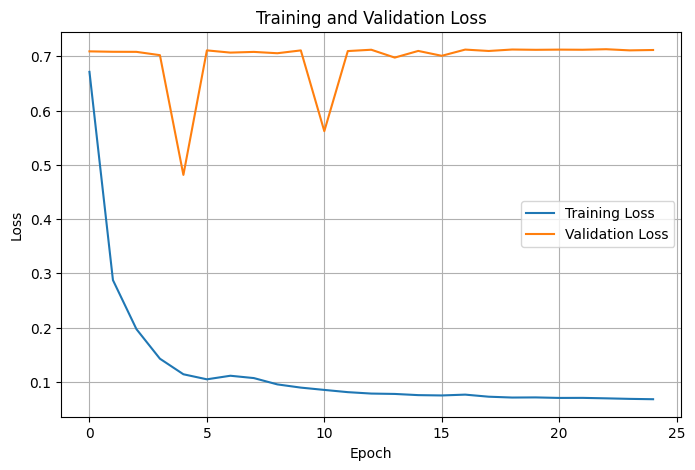

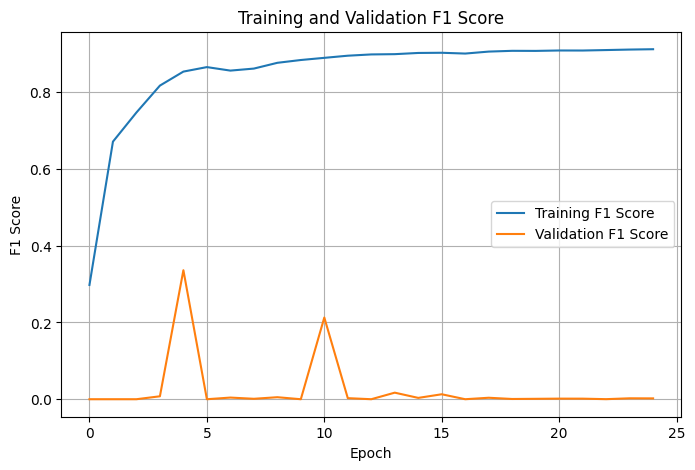

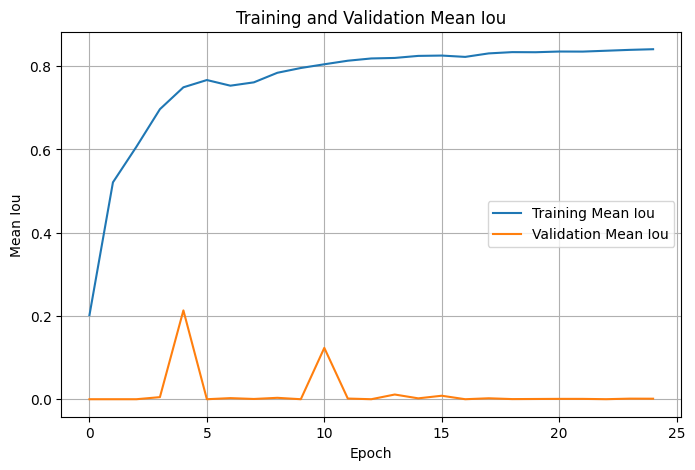

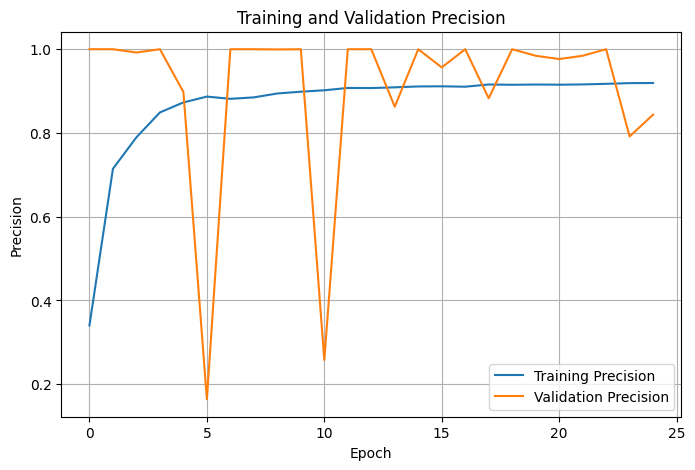

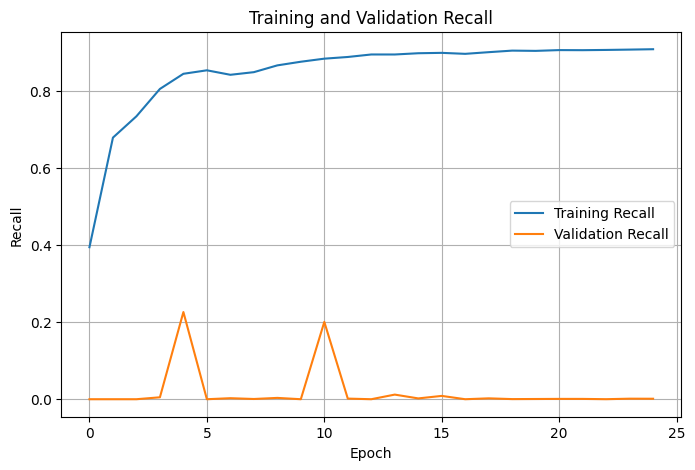

In [ ]:
plot_metrics(history)

Using device for plotting: cpu
Model loaded successfully from lightweight-UNET/pytorch/exp-10/models/final_model.pth
Reading test split from: ./HSSDataset/HSS_VOC\split\v2\test.txt
Found 302 valid image-mask pairs for split 'test'.
Created test_dataloader with batch_size=1 for plotting.


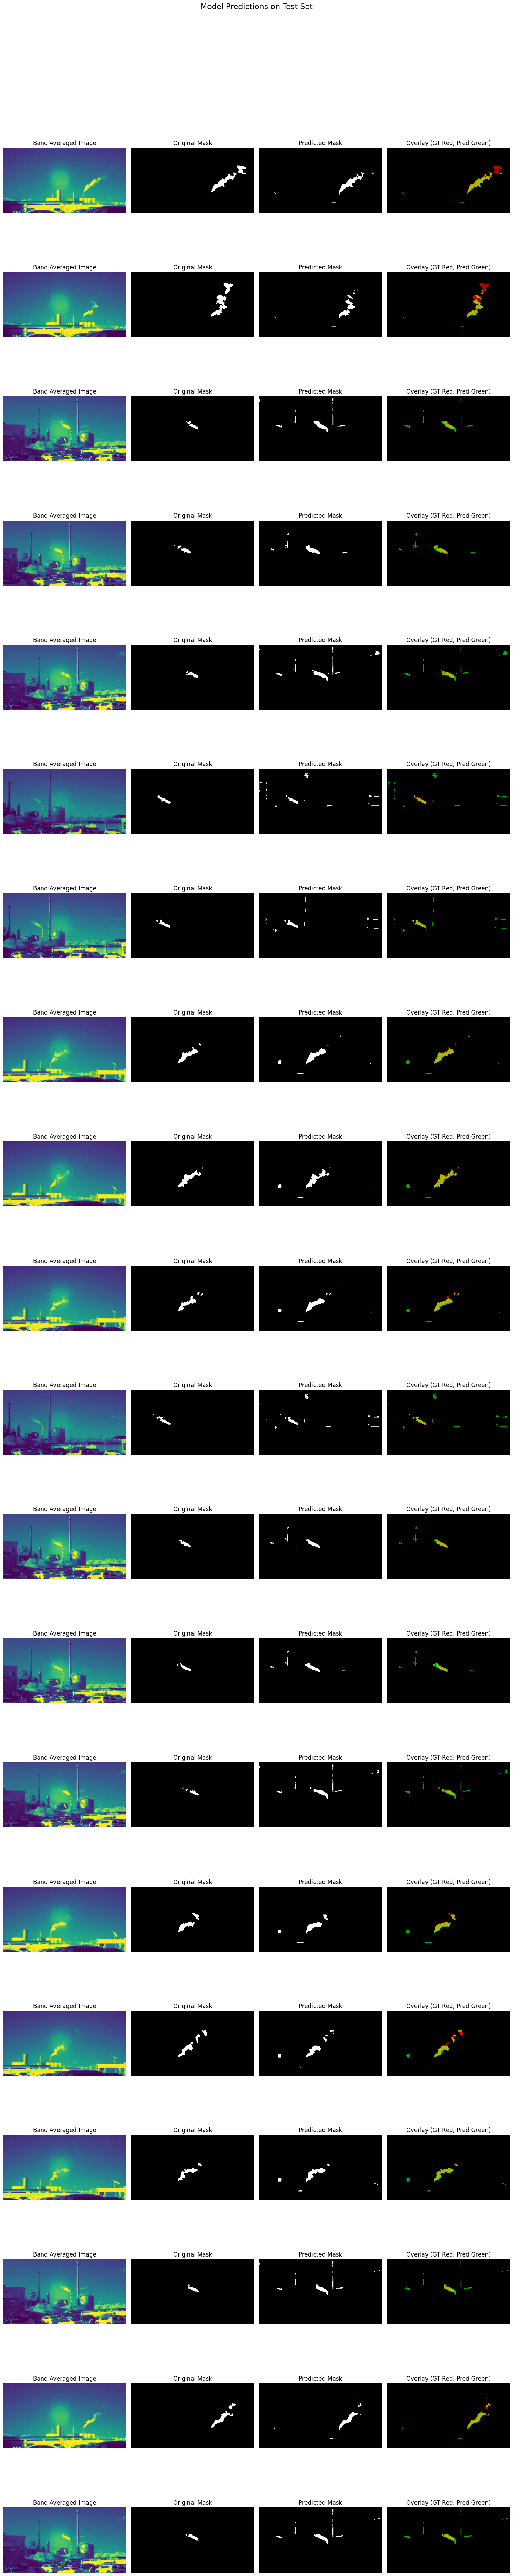

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# Assuming HSSSegmentationDatasetPyTorch and UNet are already defined (they are in the notebook)
# Assuming bce_dice_loss, f1_score, mean_iou, precision, recall are already defined
# from previous cells (fThcK4xW1-Jk and ohoJEEeF2tpt).
from torch.utils.data import DataLoader # Import DataLoader

# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device for plotting: {device}")

# Configuration parameters, consistent with training (from cell O1VIdKoexuRV)
INPUT_CHANNELS = 25 # Matches CONFIG['input_shape'][-1]
NUM_CLASSES = 1     # Matches CONFIG['num_classes']
IMAGE_HEIGHT = 216
IMAGE_WIDTH = 408

# 1. Load the saved best model
# The model was saved as 'final_model.pth' in the training cell
model_path = 'lightweight-UNET/pytorch/exp-10/models/final_model.pth'

# Instantiate the model architecture first
loaded_model = UNet(in_channels=INPUT_CHANNELS, num_classes=NUM_CLASSES)
loaded_model.to(device)

try:
    # Load the state_dict and set to evaluation mode
    loaded_model.load_state_dict(torch.load(model_path, map_location=device))
    loaded_model.eval() # Set model to evaluation mode
    print(f"Model loaded successfully from {model_path}")
except Exception as e:
    print(f"Error loading model: {e}")
    loaded_model = None

# test_segmentation_data = HSSSegmentationDatasetPyTorch2(
#     dataset_root=DATASET_ROOT,
#     split="test",
#     image_size=(216, 408),
#     data_version=DATA_VERSION
# )

# test_dataloader = DataLoader(
#     test_segmentation_data, 
#     batch_size=BATCH_SIZE, 
#     # shuffle=True
# )


if loaded_model:
    # 2. Get random images from the test set
    # Always create a new test_dataset with batch_size=1 for individual predictions
    # test_dataset_for_plot = HSSSegmentationDatasetPyTorch2(
    #     dataset_root=DATASET_ROOT,
    #     image_dir="npy_multichannel",
    #     mask_dir="masks",
    #     image_size=(IMAGE_HEIGHT, IMAGE_WIDTH), # Ensure this matches training input_shape
    #     split="test",
    #     img_channels=INPUT_CHANNELS,
    #     mask_channels=NUM_CLASSES
    # )
    test_dataset_for_plot = HSSSegmentationDatasetPyTorch2(
    dataset_root=DATASET_ROOT,
    split="test",
    image_size=(216, 408),
    data_version=DATA_VERSION
)
    # Use batch size 1 for individual prediction and plotting, shuffle for random selection
    test_dataloader_for_plot = DataLoader(test_dataset_for_plot, batch_size=1, shuffle=True, num_workers=0)
    print("Created test_dataloader with batch_size=1 for plotting.")

    # Collect a few samples to pick from
    sample_images = [] # These will be PyTorch tensors (C, H, W)
    sample_masks = []  # These will be PyTorch tensors (1, H, W)

    # Iterate through dataloader to get samples
    for i, (img_tensor, msk_tensor) in enumerate(test_dataloader_for_plot):
        if i >= 50: # Take up to 50 samples to choose from
            break
        # img_tensor now has shape (1, C, H, W), msk_tensor has (1, 1, H, W)
        sample_images.append(img_tensor.squeeze(0)) # Remove batch dim, keep (C, H, W)
        sample_masks.append(msk_tensor.squeeze(0))  # Remove batch dim, keep (1, H, W)
    
    k = 20

    if len(sample_images) < k:
        print(f"Not enough samples in test set ({len(sample_images)} found). Cannot plot 5 random images.")
    else:
        # Choose 5 random indices
        random_indices = random.sample(range(len(sample_images)), k)

        plt.figure(figsize=(15, 4 * k)) # k rows for k samples, 4 units height per row
        plt.suptitle("Model Predictions on Test Set", fontsize=16)

        for i, idx in enumerate(random_indices):
            original_image_tensor = sample_images[idx] # (C, H, W)
            original_mask_tensor = sample_masks[idx]   # (1, H, W)

            # 3. Make prediction
            # Add batch dimension and move to device: (C, H, W) -> (1, C, H, W)
            input_image_for_pred = original_image_tensor.unsqueeze(0).to(device)

            with torch.no_grad(): # Disable gradient calculation for inference
                predicted_mask_raw = loaded_model(input_image_for_pred) # Output is (1, 1, H, W)

            # Threshold the raw prediction at 0.5 and convert to binary mask (H, W) numpy array
            predicted_mask = (predicted_mask_raw.squeeze().cpu().numpy() > 0.5).astype(np.uint8)

            # Convert original_mask_tensor to numpy for plotting: (1, H, W) -> (H, W) numpy array
            original_mask_np = original_mask_tensor.squeeze().cpu().numpy().astype(np.uint8)

            # Plotting for each random image in a 2x2 grid
            # 1. Band Averaged Image (mean across channels for visualization)
            ax = plt.subplot(k, 4, i * 4 + 1)
            # original_image_tensor is (C, H, W), permute to (H, W, C) for mean over channels
            band_averaged_image = original_image_tensor.permute(1, 2, 0).mean(dim=2).cpu().numpy()
            ax.imshow(band_averaged_image, cmap="viridis")
            ax.set_title("Band Averaged Image")
            ax.axis('off')

            # 2. Original Mask
            ax = plt.subplot(k, 4, i * 4 + 2)
            ax.imshow(original_mask_np, cmap='gray')
            ax.set_title("Original Mask")
            ax.axis('off')

            # 3. Predicted Mask
            ax = plt.subplot(k, 4, i * 4 + 3)
            ax.imshow(predicted_mask, cmap='gray')
            ax.set_title("Predicted Mask")
            ax.axis('off')

            # 4. Overlayed Mask (Ground Truth in Red, Prediction in Green)
            ax = plt.subplot(k, 4, i * 4 + 4)
            overlay_image = np.zeros((original_mask_np.shape[0], original_mask_np.shape[1], 3), dtype=np.float32)
            overlay_image[:, :, 0] = original_mask_np * 0.7 # Red channel for original mask
            overlay_image[:, :, 1] = predicted_mask * 0.7 # Green channel for predicted mask
            # Yellow where both are present (overlap)
            ax.imshow(overlay_image)
            ax.set_title("Overlay (GT Red, Pred Green)")
            ax.axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
        plt.show()